# Phân tích cảm xúc phản hồi khách hàng của ngân hàng

#Cài đặt thư viện

In [ ]:
!pip install transformers==4.40.2 datasets==2.19.1 accelerate==0.29.3 sentencepiece==0.2.0 scikit-learn matplotlib seaborn -q
print('Done installing.')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 138.0/138.0 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.0/9.0 MB 47.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 542.0/542.0 kB 27.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 297.6/297.6 kB 13.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 47.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 172.0/172.0 kB 10.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 26.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 61.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.19.0 requires huggingface-hub<2.0,>=1.2.0, but you have huggingface-hub 0.36.2 which is incompatible.
gcsfs 2025.3.0 requires fsspec==2025.3.0, but you have fsspec 2024.3.1 which i

#Import thư viện và kiểm tra GPU

In [ ]:
# Cell 2: Imports and GPU check
import os, re, random, warnings, json
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score, precision_score, recall_score

matplotlib.rcParams['font.family'] = 'DejaVu Sans'
warnings.filterwarnings('ignore')
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))

Device: cpu


#Tải dữ liệu training

In [ ]:
# 1. Cài đặt thư viện kagglehub hỗ trợ pandas nếu chưa có
# !pip install kagglehub[pandas-datasets]

!pip install kagglehub[pandas-datasets]

In [ ]:
# Dữ liệu: https://www.kaggle.com/datasets/kazanova/sentiment140
# Label: Negative = 0 | Positive = 4 | Netural = 2

import kagglehub
from kagglehub import KaggleDatasetAdapter
import re

file_path = "training.1600000.processed.noemoticon.csv"

print("Đang tự động tải và nạp bộ dữ liệu Sentiment140 bằng kagglehub...")

df = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "kazanova/sentiment140",
  file_path,
  pandas_kwargs={
      "encoding": "ISO-8859-1",
      "names": ["target", "ids", "date", "flag", "user", "text"]
  }
)

df = df.sample(n=50000, random_state=42).reset_index(drop=True)


def clean_sentiment_text(text):
    text = text.lower()

    text = re.sub(r"https?://\S+|www\S+", "", text)
    text = re.sub(r"@[A-Za-z0-9_]+", "", text)
    text = re.sub(r"[^a-z\s]", "", text)
    text = re.sub(r"\s+", " ", text).strip()

    return text


df['clean_text'] = df['text'].apply(clean_sentiment_text)

print("\n--- TẢI VÀ LÀM SẠCH DỮ LIỆU THÀNH CÔNG ---")
print(df[['text', 'clean_text']].head(5))



Đang tự động tải và nạp bộ dữ liệu Sentiment140 bằng kagglehub...
Using Colab cache for faster access to the 'sentiment140' dataset.

--- TẢI VÀ LÀM SẠCH DỮ LIỆU THÀNH CÔNG ---
                                                text  \
0             @chrishasboobs AHHH I HOPE YOUR OK!!!    
1  @misstoriblack cool , i have no tweet apps  fo...   
2  @TiannaChaos i know  just family drama. its la...   
3  School email won't open  and I have geography ...   
4                             upper airways problem    

                                          clean_text  
0                                ahhh i hope your ok  
1              cool i have no tweet apps for my razr  
2  i know just family drama its lamehey next time...  
3  school email wont open and i have geography st...  
4                              upper airways problem  


#NLP


In [ ]:
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords
from nltk.stem import SnowballStemer

# Setup

In [ ]:
!pip install torch pandas numpy matplotlib scikit-learn transformers tqdm -q

In [ ]:
import os
import re
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.optim import AdamW
from torch.utils.data import Dataset, DataLoader

from transformers import (
    AutoTokenizer,
    AutoModel,
    get_linear_schedule_with_warmup
)

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

In [ ]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

Device: cuda


# Data

In [ ]:
path = kagglehub.dataset_download("kazanova/sentiment140")
print("Path to dataset files:", path)

100%|██████████| 80.9M/80.9M [00:02<00:00, 31.2MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/kazanova/sentiment140/versions/2


In [ ]:
columns = ["target", "ids", "date", "flag", "user", "text"]

df = pd.read_csv(
    path + '/training.1600000.processed.noemoticon.csv',
    encoding="latin-1",
    names=columns
)

df = df[["target", "text"]]
df["target"] = df["target"].replace({0: 0, 4: 1})
df = df.dropna().reset_index(drop=True)

print(df.head())
print(df["target"].value_counts())
print(df.shape)

   target                                               text
0       0  @switchfoot http://twitpic.com/2y1zl - Awww, t...
1       0  is upset that he can't update his Facebook by ...
2       0  @Kenichan I dived many times for the ball. Man...
3       0    my whole body feels itchy and like its on fire 
4       0  @nationwideclass no, it's not behaving at all....
target
0    800000
1    800000
Name: count, dtype: int64
(1600000, 2)


In [ ]:
SAMPLE_PER_CLASS = 50000

negative_df = df[df["target"] == 0].sample(SAMPLE_PER_CLASS, random_state=SEED)
positive_df = df[df["target"] == 1].sample(SAMPLE_PER_CLASS, random_state=SEED)

df = pd.concat([negative_df, positive_df])
df = df.sample(frac=1, random_state=SEED).reset_index(drop=True)

print(df["target"].value_counts())
print(df.shape)

target
1    50000
0    50000
Name: count, dtype: int64
(100000, 2)


# Preprocessing


In [ ]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", " url ", text)
    text = re.sub(r"@\w+", " user ", text)
    text = text.replace("can't", "can not")
    text = text.replace("won't", "will not")
    text = text.replace("n't", " not")
    text = text.replace("'re", " are")
    text = text.replace("'s", " is")
    text = text.replace("'d", " would")
    text = text.replace("'ll", " will")
    text = text.replace("'t", " not")
    text = text.replace("'ve", " have")
    text = text.replace("'m", " am")
    text = re.sub(r"[^a-zA-Z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text
df["clean_text"] = df["text"].apply(clean_text)
df.head()

,target,text,clean_text
0,1,@stargazer60 that's awesome,user that is awesome
1,1,@cunningstunts22 yes... i am!,user yes i am
2,0,N my bed aaallll alone,n my bed aaallll alone
3,1,@Thorney88 re guinea fowl ive heard that lots ...,user re guinea fowl ive heard that lots of peo...
4,1,def going to the movies tonite,def going to the movies tonite


In [ ]:
X = df["clean_text"].values
y = df["target"].values

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=SEED,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print("Train:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))

Train: 70000
Validation: 15000
Test: 15000


# Model Setup

In [ ]:
MODEL_NAME = "distilbert-base-uncased"
MAX_LEN = 80
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
print("Tokenizer loaded:", MODEL_NAME)
print("Vocab size:", tokenizer.vocab_size)

Tokenizer loaded: distilbert-base-uncased
Vocab size: 30522


In [ ]:
class SentimentDataset(Dataset):
    def __init__(self, texts, labels):
        self.texts = texts
        self.labels = labels

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, ix):
        encoding = tokenizer(
            self.texts[ix],
            max_length = MAX_LEN,
            padding = "max_length",
            truncation = True,
            return_tensors = "pt"
        )

        input_ids = encoding["input_ids"].squeeze(0)
        attention_mask = encoding["attention_mask"].squeeze(0)
        label = torch.tensor(self.labels[ix], dtype=torch.long)

        return (
            input_ids.to(device),
            attention_mask.to(device),
            label.to(device)
        )

In [ ]:
def get_data(batch_size=32):
    train_ds = SentimentDataset(X_train, y_train)
    val_ds = SentimentDataset(X_val, y_val)
    test_ds = SentimentDataset(X_test, y_test)
    trn_dl = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    val_dl = DataLoader(val_ds, batch_size=batch_size, shuffle=False)
    test_dl= DataLoader(test_ds, batch_size=batch_size, shuffle=False)

    return trn_dl, val_dl, test_dl

trn_dl, val_dl, test_dl = get_data(batch_size=32)

In [ ]:
class BERTSentimentClassifier(nn.Module):
    def __init__(self, model_name, output_dim, dropout=0.3):
        super().__init__()

        self.bert = AutoModel.from_pretrained(model_name)

        hidden_size = self.bert.config.hidden_size

        for param in self.bert.parameters():
            param.requires_grad = False

        self.dropout1 = nn.Dropout(dropout)
        self.fc1 = nn.Linear(hidden_size, 256)
        self.bn = nn.BatchNorm1d(256)
        self.dropout2 = nn.Dropout(dropout)
        self.fc2 = nn.Linear(256, output_dim)

    def forward(self, input_ids, attention_mask):
        outputs = self.bert(
            input_ids = input_ids,
            attention_mask = attention_mask
        )

        cls_output = outputs.last_hidden_state[:, 0, :]

        x = self.dropout1(cls_output)
        x = torch.relu(self.fc1(x))
        x = self.bn(x)
        x = self.dropout2(x)
        x = self.fc2(x)

        return x

    def unfreeze_top_n_layers(self, n):
        transformer_layers = self.bert.transformer.layer
        total = len(transformer_layers)

        for param in self.bert.parameters():
            param.requires_grad = False

        for i in range(total - n, total):
            for param in transformer_layers[i].parameters():
                param.requires_grad = True

        if n >= total:
            for param in self.bert.embeddings.parameters():
                param.requires_grad = True

        trainable = sum(p.numel() for p in self.parameters() if p.requires_grad)
        print(f"Unfreeze top {n}/{total} layers | Tham số huẩn luyện phù hợp: {trainable:,}")

In [ ]:
def get_model():
    model = BERTSentimentClassifier(
        model_name = MODEL_NAME,
        output_dim = 2,
        dropout = 0.30
    ).to(device)
    loss_fn = nn.CrossEntropyLoss()
    return model, loss_fn

model, loss_fn = get_model()

optimizer = AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr = 2e-4,
    weight_decay = 1e-2
)

print(model)

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BERTSentimentClassifier(
  (bert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSelfAttention(
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
          (ffn): FFN(
            (dropout): Dropout(p=0.1, inplace=False)
            (lin1)

# Training


In [ ]:
def train_batch(x_ids, x_mask, y, model, optimizer, loss_fn):
    model.train()
    prediction = model(x_ids, x_mask)
    batch_loss = loss_fn(prediction, y)
    batch_loss.backward()
    torch.nn.utils.clip_grad_norm_(
        model.parameters(),
        max_norm=1.0
    )
    optimizer.step()
    optimizer.zero_grad()
    return batch_loss.item()


@torch.no_grad()
def accuracy(x_ids, x_mask, y, model):
    model.eval()
    prediction = model(x_ids, x_mask)
    _, argmaxes = prediction.max(dim=1)
    is_correct = argmaxes == y
    return is_correct.cpu().numpy().tolist()


@torch.no_grad()
def calculate_loss(x_ids, x_mask, y, model, loss_fn):
    model.eval()
    prediction = model(x_ids, x_mask)
    loss = loss_fn(prediction, y)
    return loss.item()

In [ ]:

EPOCHS    = 20
PATIENCE  = 5
MIN_DELTA = 0.0005

UNFREEZE_SCHEDULE = {
    1:  (0,    2e-4,  1e-2),
    3:  (2,    5e-5,  5e-3),
    5:  (4,    2e-5,  1e-3),
    7:  (6,    5e-6,  1e-4),
}

best_model_path = "best_sentiment_bert.pt"

if os.path.exists(best_model_path):
    os.remove(best_model_path)

train_losses, train_accuracies = [], []
val_losses, val_accuracies = [], []

best_val_loss = float("inf")
best_val_acc = 0
best_epoch = 0
counter = 0

current_lr = 2e-4
optimizer = AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=current_lr, weight_decay=1e-2
)

def make_scheduler(opt, num_warmup, num_training):
    return get_linear_schedule_with_warmup(
        opt,
        num_warmup_steps  = num_warmup,
        num_training_steps= num_training
    )

steps_per_epoch = len(trn_dl)
scheduler = make_scheduler(optimizer, steps_per_epoch, steps_per_epoch * 2)

epoch_bar = tqdm(range(1, EPOCHS + 1), desc="Epochs", position=0)

for epoch in epoch_bar:
    print(f"\n{'='*55}")
    print(f"Epoch {epoch}/{EPOCHS}")

    if epoch in UNFREEZE_SCHEDULE:
        n_layers, new_lr, new_wd = UNFREEZE_SCHEDULE[epoch]

        model.unfreeze_top_n_layers(n_layers)

        optimizer = AdamW(
            filter(lambda p: p.requires_grad, model.parameters()),
            lr=new_lr, weight_decay=new_wd
        )

        remaining_epochs = EPOCHS - epoch + 1
        scheduler = make_scheduler(
            optimizer,
            num_warmup = steps_per_epoch,
            num_training = steps_per_epoch * remaining_epochs
        )

        current_lr = new_lr
        print(f"  → New LR: {new_lr} | WD: {new_wd}")

    # ── Train
    train_epoch_losses = []
    train_epoch_accuracies = []

    train_bar = tqdm(trn_dl, desc=f"Train", leave=False, position=1)

    for x_ids, x_mask, y in train_bar:
        batch_loss = train_batch(x_ids, x_mask, y, model, optimizer, loss_fn)
        train_epoch_losses.append(batch_loss)

        is_correct = accuracy(x_ids, x_mask, y, model)
        train_epoch_accuracies.extend(is_correct)

        scheduler.step()

        train_bar.set_postfix(loss=f"{batch_loss:.4f}", acc=f"{np.mean(train_epoch_accuracies):.4f}")

    # ── Validation
    val_epoch_losses = []
    val_epoch_accuracies = []

    val_bar = tqdm(val_dl, desc=f" Val ", leave=False, position=1)

    for x_ids, x_mask, y in val_bar:
        val_loss = calculate_loss(x_ids, x_mask, y, model, loss_fn)
        val_epoch_losses.append(val_loss)

        val_is_correct = accuracy(x_ids, x_mask, y, model)
        val_epoch_accuracies.extend(val_is_correct)

        val_bar.set_postfix(loss=f"{val_loss:.4f}", acc=f"{np.mean(val_epoch_accuracies):.4f}")

    train_epoch_loss = np.mean(train_epoch_losses)
    train_epoch_accuracy = np.mean(train_epoch_accuracies)

    val_epoch_loss = np.mean(val_epoch_losses)
    val_epoch_accuracy = np.mean(val_epoch_accuracies)

    train_losses.append(train_epoch_loss)
    train_accuracies.append(train_epoch_accuracy)
    val_losses.append(val_epoch_loss)
    val_accuracies.append(val_epoch_accuracy)

    gap = train_epoch_accuracy - val_epoch_accuracy
    gap_flag = "overfit?" if gap > 0.04 else ""

    print(f"Train Loss: {train_epoch_loss:.4f} | Train Acc: {train_epoch_accuracy:.4f}")
    print(f"Val Loss: {val_epoch_loss:.4f} | Val Acc: {val_epoch_accuracy:.4f}  |  Gap: {gap:+.4f}{gap_flag}")
    print(f"LR: {optimizer.param_groups[0]['lr']:.2e}")

    epoch_bar.set_postfix(
        val_loss=f"{val_epoch_loss:.4f}",
        val_acc=f"{val_epoch_accuracy:.4f}",
        best=best_epoch
    )

    if val_epoch_loss < best_val_loss - MIN_DELTA:
        best_val_loss = val_epoch_loss
        best_val_acc = val_epoch_accuracy
        best_epoch = epoch
        counter = 0

        torch.save(model.state_dict(), best_model_path)
        print("Saved best model!")
    else:
        counter += 1
        print(f"No improvement: {counter}/{PATIENCE}")

    if counter >= PATIENCE:
        print("Early stopping!")
        break

print(f"\nBest Epoch: {best_epoch}")
print(f"Best Val Loss: {best_val_loss:.4f}")
print(f"Best Val Acc: {best_val_acc:.4f}")

Epochs:   0%|          | 0/20 [00:00<?, ?it/s]


Epoch 1/20
  Unfreeze top 0/6 layers | Tham số huẩn luyện phù hợp: 197,890
  → New LR: 0.0002 | WD: 0.01


  Train:   0%|          | 0/2188 [00:00<?, ?it/s]

 Val :   0%|          | 0/469 [00:00<?, ?it/s]

Train Loss: 0.5899 | Train Acc: 0.7371
Val Loss:   0.5022 | Val Acc:   0.7572  |  Gap: -0.0201
LR: 2.00e-04
Saved best model!

Epoch 2/20


...

 Val :   0%|          | 0/469 [00:00<?, ?it/s]

Train Loss: 0.2353 | Train Acc: 0.9353
Val Loss:   0.4742 | Val Acc:   0.8192  |  Gap: +0.1161overfit?
LR: 4.62e-06
No improvement: 4/5

Epoch 9/20


  Train:   0%|          | 0/2188 [00:00<?, ?it/s]

 Val :   0%|          | 0/469 [00:00<?, ?it/s]

Train Loss: 0.2015 | Train Acc: 0.9546
Val Loss:   0.5359 | Val Acc:   0.8175  |  Gap: +0.1371overfit?
LR: 4.23e-06
No improvement: 5/5
Early stopping!

Best Epoch: 4
Best Val Loss: 0.3986
Best Val Acc: 0.8205


# Evaluation and infernce

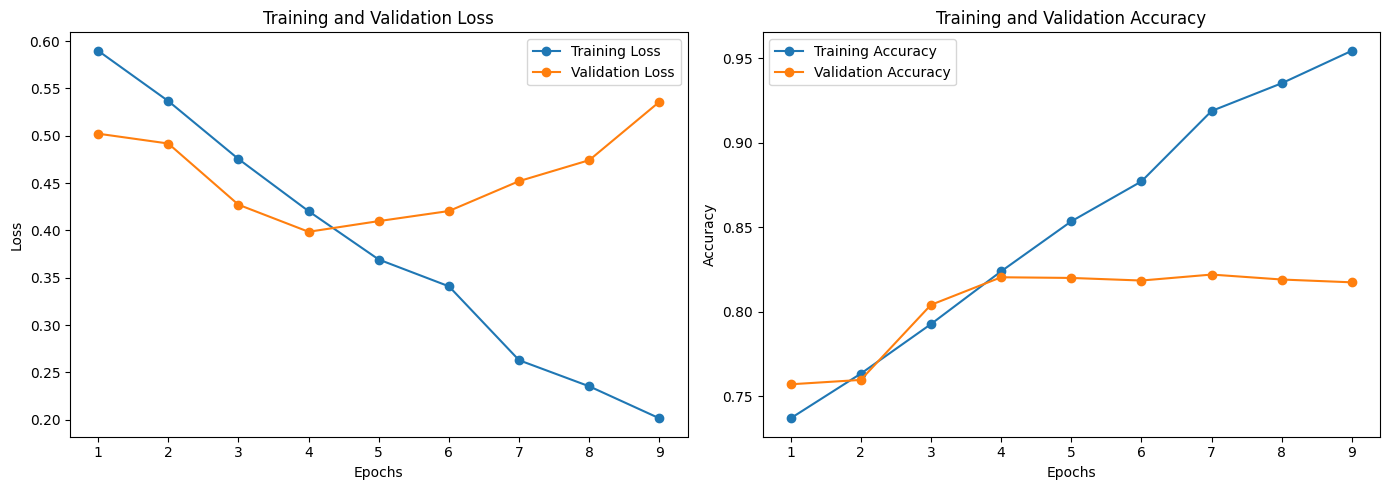

In [ ]:
epochs_axis = np.arange(len(train_losses)) + 1

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_axis, train_losses, marker="o", label="Training Loss")
plt.plot(epochs_axis, val_losses, marker="o", label="Validation Loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs_axis, train_accuracies, marker="o", label="Training Accuracy")
plt.plot(epochs_axis, val_accuracies, marker="o", label="Validation Accuracy")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
best_model, loss_fn = get_model()
best_model.load_state_dict(
    torch.load(best_model_path, map_location=device)
)
best_model.to(device)
best_model.eval()

test_losses = []
test_accuracies = []
all_preds = []
all_labels = []

with torch.no_grad():
    test_bar = tqdm(test_dl, desc="Evaluating test set")

    for x_ids, x_mask, y in test_bar:
        prediction = best_model(x_ids, x_mask)
        loss = loss_fn(prediction, y)
        test_losses.append(loss.item())
        preds = prediction.argmax(dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(y.cpu().numpy())
        is_correct = preds == y
        test_accuracies.extend(is_correct.cpu().numpy())
        test_bar.set_postfix(
            loss=f"{np.mean(test_losses):.4f}",
            acc=f"{np.mean(test_accuracies):.4f}"
        )

test_loss = np.mean(test_losses)
test_accuracy = np.mean(test_accuracies)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Evaluating test set:   0%|          | 0/469 [00:00<?, ?it/s]

Test Loss: 0.39192655352132916
Test Accuracy: 0.8223333333333334


In [ ]:
print(classification_report(
    all_labels,
    all_preds,
    target_names=["Negative", "Positive"]
))

print("Confusion Matrix:")
print(confusion_matrix(all_labels, all_preds))

              precision    recall  f1-score   support

    Negative       0.82      0.83      0.82      7500
    Positive       0.83      0.81      0.82      7500

    accuracy                           0.82     15000
   macro avg       0.82      0.82      0.82     15000
weighted avg       0.82      0.82      0.82     15000

Confusion Matrix:
[[6235 1265]
 [1400 6100]]


In [ ]:
def predict_sentiment(text):
    best_model.eval()

    cleaned  = clean_text(text)

    encoding = tokenizer(
        cleaned,
        max_length = MAX_LEN,
        padding = "max_length",
        truncation = True,
        return_tensors = "pt"
    )

    input_ids = encoding["input_ids"].to(device)
    attention_mask = encoding["attention_mask"].to(device)

    with torch.no_grad():
        output = best_model(input_ids, attention_mask)
        prob = torch.softmax(output, dim=1)
        pred = torch.argmax(prob, dim=1).item()

    label = "Positive" if pred == 1 else "Negative"

    return label, prob.cpu().numpy()[0]


samples = [
    "The banking service is very good and the staff are helpful",
    "I am very disappointed because my transaction failed many times",
    "The mobile banking app is fast and easy to use",
    "Customer support is terrible and I waited too long",
    "The bank solved my complaint quickly",
    "The service fee is too high and the app often crashes"
]

for s in samples:
    label, prob = predict_sentiment(s)

    print("Text:", s)
    print("Prediction:", label)
    print("Negative Probability:", f"{prob[0]:.4f}")
    print("Positive Probability:", f"{prob[1]:.4f}")
    print("-" * 50)

Text: The banking service is very good and the staff are helpful
Prediction: Positive
Negative Probability: 0.0345
Positive Probability: 0.9655
--------------------------------------------------
Text: I am very disappointed because my transaction failed many times
Prediction: Negative
Negative Probability: 0.9837
Positive Probability: 0.0163
--------------------------------------------------
Text: The mobile banking app is fast and easy to use
Prediction: Positive
Negative Probability: 0.0840
Positive Probability: 0.9160
--------------------------------------------------
Text: Customer support is terrible and I waited too long
Prediction: Negative
Negative Probability: 0.9777
Positive Probability: 0.0223
--------------------------------------------------
Text: The bank solved my complaint quickly
Prediction: Negative
Negative Probability: 0.7398
Positive Probability: 0.2602
--------------------------------------------------
Text: The service fee is too high and the app often crashes
Pr